# Project Part 3

- Team 7
- Henry Lai, Hirna Derege, Fatimah Abdullahi, Kimi Yokoyama
- Smart Healthcare and Lifestyle Prediction Dataset
- Target Variable: Heart_Disease
- Main Modeling Goal: Train a model to predict heart disease using patient medical records, free from the biases that have historically affected medical diagnosis in the US. The goal is for predictions to be based purely on clinical indicators rather than subjective human judgment.

# Problem Setup

**About the Dataset**

Our chosen dataset represents patient portfolios and profiles to simulate real-world healthcare scenarios. Diverse information about everyone is provided, allowing insight into lifestyle, medical background, and demographic factors that might contribute to the overall health of the patient. Examples of these factors include gender, alcohol usage, and the presence of a stroke in medical history. This dataset is formatted as a .csv, containing only tabular, numeric data, with some of the variables being binary. It is a singular file, not yet separated into training and testing data, with 5,000 entries or rows.

**About the Problem**

The goal of diagnostic medicine is to take all necessary information about a patient and come up with a medical diagnosis. "Situated knowledge," a term coined by Donna Haraway, is the idea that all knowledge comes with bias that originates from the knower. We see these biases throughout the history of medicine in the US, contributing to racial disparities in diagnosis, treatment, and patient-provider trust. Our team goal is to train a model that can calculate a health score that would be solely based on medical records, free from bias.

**Target Variable**

Heart_Disease

**Main Input Features**

Age, Gender, BMI, Exercise_Level, Smoking, Alcohol, Blood_Pressure, Cholesterol, Glucose, Fatigue, Chest_Pain, Dizziness, Diabetes, Stroke

**Main Modeling Goal**

Train a model to predict heart disease using patient medical records, free from the biases that have historically affected medical diagnosis in the US. The goal is for predictions to be based purely on clinical indicators rather than subjective human judgment.

# Data Preparation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('smart_healthcare_dataset.csv')
df.head()

,age,gender,bmi,exercise_level,smoking,alcohol,blood_pressure,cholesterol,glucose,fatigue,chest_pain,dizziness,heart_disease,diabetes,stroke,health_risk_score
0,56,Male,22.6,2,1,1,169,225,74,0,1,0,0,0,0,100.0
1,69,Female,28.2,0,1,1,136,230,198,0,1,0,1,1,1,100.0
2,46,Female,25.1,1,0,1,142,221,89,0,1,1,0,0,0,100.0
3,32,Female,18.0,0,0,1,173,296,152,1,0,0,0,0,0,100.0
4,60,Female,20.1,2,1,0,130,292,133,1,1,1,0,1,0,100.0


In [ ]:
# Checking for Missing Values
print(df.isna().sum())
print(f"\nTotal missing: {df.isna().sum().sum()}")

age                  0
gender               0
bmi                  0
exercise_level       0
smoking              0
alcohol              0
blood_pressure       0
cholesterol          0
glucose              0
fatigue              0
chest_pain           0
dizziness            0
heart_disease        0
diabetes             0
stroke               0
health_risk_score    0
dtype: int64

Total missing: 0


In [ ]:
# Checking for Invalid Zeros
zero_check_cols = ['bmi', 'blood_pressure', 'cholesterol', 'glucose', 'health_risk_score']
print((df[zero_check_cols] == 0).sum())
# For gender specifically
print(df['gender'].value_counts())

bmi                  0
blood_pressure       0
cholesterol          0
glucose              0
health_risk_score    0
dtype: int64
gender
Female    2506
Male      2494
Name: count, dtype: int64


In [ ]:
# Checking for Inconsistent Labeling

# Categorical
print(df['gender'].unique())

# Binary columns
binary_cols = ['exercise_level', 'smoking', 'alcohol', 'fatigue',
               'chest_pain', 'dizziness', 'diabetes', 'stroke', 'heart_disease']
for col in binary_cols:
    print(f"{col}: {sorted(df[col].unique())}")

# Range checks
range_checks = {
    'age': (18, 79), 'bmi': (0, 200), 'blood_pressure': (1, 250),
    'cholesterol': (1, 500), 'glucose': (1, 500)
}
for col, (lo, hi) in range_checks.items():
    out = df[(df[col] < lo) | (df[col] > hi)]
    print(f"{col} out of range: {len(out)}")

['Male' 'Female']
exercise_level: [np.int64(0), np.int64(1), np.int64(2)]
smoking: [np.int64(0), np.int64(1)]
alcohol: [np.int64(0), np.int64(1)]
fatigue: [np.int64(0), np.int64(1)]
chest_pain: [np.int64(0), np.int64(1)]
dizziness: [np.int64(0), np.int64(1)]
diabetes: [np.int64(0), np.int64(1)]
stroke: [np.int64(0), np.int64(1)]
heart_disease: [np.int64(0), np.int64(1)]
age out of range: 0
bmi out of range: 0
blood_pressure out of range: 0
cholesterol out of range: 0
glucose out of range: 0


In [ ]:
# Checking for Duplicate Values
print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 0


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['gender'] = le.fit_transform(df['gender'])

**Preprocessing Decisions**

- From our previous assignment, Project Pt. 2, we stated that we don't have any invalid entries in our dataset. The only challenge that may be present was handling invalid zero values through imputation or filtering, and applying feature scaling for models sensitive to differences in magnitude. Potential class imbalance in the Heart_Disease variable may require resampling techniques or adjusted evaluation metrics. Additionally, model selection will involve balancing interpretability (such as logistic regression) with predictive performance (such as tree-based models), while also addressing any multicollinearity between features.
- The code above is to support our claim that we don't have any invalid entries by checking isna().sum(), zero counts, label counts, and duplicate
- An additional preprocessing implementation was the LabelEncoder(). This helped transform the string value of gender to binary so we are able to do model training

# Model Training


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Label encode gender before splitting
le = LabelEncoder()
df['gender'] = le.fit_transform(df['gender'])

# Features and target
features = ['age', 'gender', 'bmi', 'exercise_level', 'smoking', 'alcohol',
            'blood_pressure', 'cholesterol', 'glucose', 'fatigue',
            'chest_pain', 'dizziness', 'diabetes', 'stroke']

X = df[features]
y = df['heart_disease']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale all features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Model 1: Logistic Regression (Baseline)
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
lr_preds = lr.predict(X_test_scaled)

print("Logistic Regression")
print(f"Accuracy: {accuracy_score(y_test, lr_preds):.4f}")
print(classification_report(y_test, lr_preds))

Logistic Regression
Accuracy: 0.9880
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       690
           1       0.98      0.98      0.98       310

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



In [ ]:
# Model 2: Naive Bayes
# GaussianNB works on numerical values, so we should use the scaled/processed data.
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)
nb_preds = nb.predict(X_test_scaled)

print("Naive Bayes")
print(f"Accuracy: {accuracy_score(y_test, nb_preds):.4f}")
print(classification_report(y_test, nb_preds))

Naive Bayes
Accuracy: 0.9480
              precision    recall  f1-score   support

           0       0.99      0.93      0.96       690
           1       0.86      0.99      0.92       310

    accuracy                           0.95      1000
   macro avg       0.93      0.96      0.94      1000
weighted avg       0.95      0.95      0.95      1000



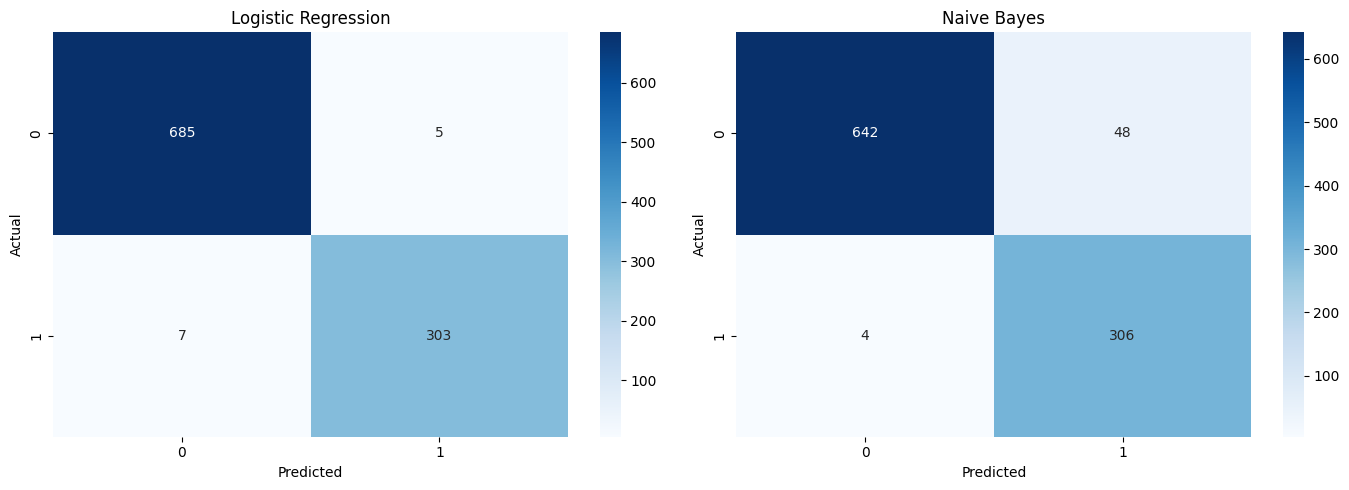

In [ ]:
# Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# zip() is used to combine multiple iterables
for ax, preds, title in zip(axes, [lr_preds, nb_preds], ['Logistic Regression', 'Naive Bayes']):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

# Evaluation

We evaluated both models on the test set using accuracy, precision, recall, and F1-score. Since this is a healthcare prediction problem, our main evaluation metric is the F1-score because it balances both precision and recall.


In medical prediction, accuracy alone is not enough. A model could appear highly accurate while still missing patients who actually have heart disease. Recall is important because false negatives could delay treatment, while precision matters because too many false positives can lead to unnecessary testing. The F1-score combines both concerns into a single metric, making it the most useful measure for this problem.

###**Logistic Regression**

>Accuracy: 98.8%  

>Precision: 0.98  

>Recall: 0.98  

>F1-score: 0.98  

Logistic Regression performed extremely well and maintained a strong balance between correctly identifying heart disease cases and avoiding incorrect predictions.

###**Naive Bayes**

>Accuracy: 94.8%  

>Precision: 0.86  

>Recall: 0.99  

>F1-score: 0.92  

Naive Bayes detected nearly all heart disease cases, but it produced more false positives than Logistic Regression.

###**Overall Interpretation**

Logistic Regression performed better overall because it achieved the highest F1-score and the best balance between precision and recall. This makes it the more reliable model for predicting heart disease in our dataset.

# Visual Evidence and Error Analysis

The confusion matrices give us a bit of a clearer picture of how each model performed on the test data. Logistic regression correctly classified the vast majority of both healthy and heart disease cases, with very few false positives or false negatives. This demonstrates that the model generalized well to this unseen data.

Naive Bayes also performed reasonably well, but the confusion matrix showed a larger number of false positive predictions. This explains the lower precision score for class 1. The model tended to overpredict the presence of heart disease, which may be caused by the strong independence assumptions made by naive Bayes.

One noticeable pattern is that both models were slightly better at predicting class 0 than class 1. This may be partially due to the dataset containing more non-heart-disease examples than heart disease examples. In addition, some features in the dataset may overlap significantly between healthy and at-risk patients, making classification more difficult.

Another limitation is that healthcare datasets often contain noisy or correlated variables. Logistic regression appears to handle these relationships more effectively, while naive Bayes may struggle because it assumes that all features are conditionally independent.

Despite these limitations, both models demonstrated strong predictive ability overall, suggesting that the selected features contain meaningful information related to heart disease risk.


# Interpretation and Comparison

Between the two tested models, logistic regression performed better overall. It achieved higher accuracy, higher precision, and more balanced recall values across both classes. The evaluation metrics and confusion matrices both support this conclusion.

The logistic regression model likely performed better because many healthcare-related variables have relationships that are approximately linear when predicting disease risk (like how the more you smoke, the more you are at risk for lung cancer, for example). Features such as cholesterol, glucose, BMI, smoking status, exercise frequency, and blood pressure all contribute in ways that logistic regression can model effectively.

Naive Bayes still performed reasonably well and demonstrated excellent recall for detecting heart disease cases. However, the model produced more false positives because it assumes that all features are independent from one another. In reality, many healthcare variables are correlated. For example, cholesterol, blood pressure, BMI, and diabetes status are often related. Because naive Bayes ignores these relationships, its predictions were less balanced.

Our feature choices appear to have contributed strongly to the model performance. Variables connected to cardiovascular health, lifestyle habits, and medical history all likely provided important predictive information. The inclusion of both biological and behavioral features helped the models capture multiple dimensions of health risk.

One strength of the logistic regression model is its interpretability. Since logistic regression produces coefficients for each feature, it is easier to understand how different variables influence predictions. This is especially important in healthcare applications where interpretability and transparency matter.

One area where both models struggled slightly was distinguishing borderline cases where patients may share characteristics of both healthy and at-risk groups. This likely contributed to the remaining classification errors.

Overall, the results suggest that supervised learning models can effectively predict heart disease risk using lifestyle and medical data, with logistic regression providing the strongest overall performance in this project.



#Reflection
This project helped us better understand the complete supervised machine learning workflow, from preprocessing and feature selection to model evaluation and interpretation. One of the most important lessons we learned was that evaluation metrics must match the problem context. Although accuracy is useful, healthcare problems also require extra careful consideration of recall and precision because prediction mistakes can have real-world consequences.

We also learned the importance of comparing models rather than relying on a single approach. By testing both logistic regression and naive Bayes, we were able to better understand how different algorithms behave on the same dataset. Logistic regression produced more balanced and reliable predictions, while naive Bayes highlighted how model assumptions can affect performance.

Another major takeaway was the importance of data preparation. Proper preprocessing, scaling, and handling of categorical variables played a significant role in achieving strong model performance. Even relatively simple models can perform very well when the data is prepared carefully.

One limitation of our project is that the dataset may not fully represent real-world healthcare populations. Additionally, there may be hidden biases or correlations within the data that affect the model’s predictions. Future improvements could include testing additional models such as decision trees or random forests, performing feature importance analysis, or using cross-validation to improve reliability.

Overall, this project demonstrated how machine learning can be applied to healthcare prediction problems and showed the importance of balancing predictive performance with interpretability and responsible evaluation.